In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
from pathlib import Path
import seaborn as sns
from collections import defaultdict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import copy
import torch
import torch.nn as nn
from tqdm.notebook import tqdm
from sklearn.preprocessing import StandardScaler

import import_ipynb
import os
curdir = os.getcwd()
src_path = Path('../src/')
os.chdir(src_path)
from ML_Base import XANESVisualizer
from Wrappers import LinRegWrapper, TreeBaggingWrapper
os.chdir(curdir)

## Загрузка данных

In [2]:
cn_df = pd.read_csv('../source_data/DataFromJPCLett.2017/CN_DATA.csv').drop(columns='Unnamed: 0')

np_info = pd.read_pickle('../processed_data/NP_info.pkl')
np_basis =  pd.read_pickle('../source_data/NP_basis_representation_from_substructures.pkl')
np_basis = np_basis.sort_values(by='NP_index', ascending=True)
np_info = np_info[['NP_index','shape','n_atoms','Pair_init_size']]
np_info['NP_index'] = np_info['NP_index'].astype(int)
np_df = np_basis.merge(np_info, how='left', left_on='NP_index', right_on='NP_index')

In [3]:
X_train = np.load('../processed_data/DataSets/Scenario_3_Train_X.npz')['arr_0']
y_train = np.load('../processed_data/DataSets/Scenario_3_Train_y.npz')['arr_0']

X_test = np.load('../processed_data/DataSets/Scenario_3_Test_X.npz')['arr_0']
y_test = np.load('../processed_data/DataSets/Scenario_3_Test_y.npz')['arr_0']

X_val = np.load('../processed_data/DataSets/Scenario_3_Val_X.npz')['arr_0']
y_val = np.load('../processed_data/DataSets/Scenario_3_Val_y.npz')['arr_0']

In [4]:
E_GRID = np.arange(-10,60.1,0.5)
norm_point_idx = 110

In [5]:
theor_foil_our = Path('../processed_data/conv_dense_spectra/2045.txt')
foil_spectrum_exp = np.loadtxt('../source_data/PtL3_foil.txt')

our_theor_foil = np.loadtxt(theor_foil_our)
our_theor_foil_interp = np.interp(E_GRID,our_theor_foil[:,0],our_theor_foil[:,1])

In [6]:
%%time

SPECTRA_ROOT = Path('../processed_data/conv_dense_spectra/')
SPECTRA_PATH_LIST = sorted(list(SPECTRA_ROOT.iterdir()), key=lambda x: int(x.name.split('.')[0]))

unique_spectra_interp_cache = {}
for path in tqdm(SPECTRA_PATH_LIST):
    ind = int(path.name.split('.')[0])
    spectra = np.loadtxt(SPECTRA_PATH_LIST[ind])
    x,y = spectra[:,0], spectra[:,1]
    new_y = np.interp(E_GRID,x,y)
    unique_spectra_interp_cache[ind]=new_y

spectra_y = np.array(list(unique_spectra_interp_cache.values()))


NP_spectra_cache = {}
for ind in tqdm(np_df.index.tolist()):
    NP_ind = np_df.NP_index.loc[ind]
    weights = np_df.Weighted_vector.loc[ind]
    weights = weights/weights.sum()
    NP_spectrum = weights@spectra_y
    NP_spectra_cache[int(NP_ind)] = NP_spectrum

  0%|          | 0/2151 [00:00<?, ?it/s]

  0%|          | 0/800 [00:00<?, ?it/s]

CPU times: total: 8.12 s
Wall time: 8.04 s


## Необходимые функции

In [7]:
def standardize_spectrum(spectrum:np.ndarray, e_interp:np.ndarray=E_GRID, norm_e_point_idx:int=110, ):
    dE = (spectrum[1:, 1] - spectrum[:-1, 1]) / (spectrum[1:, 0] - spectrum[:-1, 0]+1e-6)
    e_shift = spectrum[np.argmax(dE), 0]
    e_array = spectrum[:, 0] - e_shift
    y = np.interp(e_interp, e_array, spectrum[:,1])
    y_min = y.min()
    y -= y_min
    norm_coef = y[norm_e_point_idx]
    y = y/norm_coef
    print(f'{e_shift=}, {norm_coef=}, {y_min=}')
    return np.column_stack((e_interp,y))

In [8]:
_ = standardize_spectrum(our_theor_foil)
print('max pos in theor foil',our_theor_foil[np.argmax(our_theor_foil[:,1]),0])

e_shift=np.float64(0.25000000000014566), norm_coef=np.float64(3.708504410384543), y_min=np.float64(0.4657882112625157)
max pos in theor foil 2.450000000000177


In [9]:
def prepare_spectrum(standardized_spectrum:np.ndarray, e_interp:np.ndarray=E_GRID, norm_coef_theor:float=3.709, y_min:float=0.466, max_pos:float=2.45):
    spectrum = standardized_spectrum.copy()
    max_pos_dif = spectrum[np.argmax(spectrum[:,1]),0] - max_pos
    x = spectrum[:,0] - max_pos_dif
    y = spectrum[:,1] * norm_coef_theor + y_min
    y =  np.interp(e_interp, x, y)
    return np.column_stack((e_interp,y))

In [10]:
def plot_spectrum(target_size, save_root='../images/'):
    dif = 5
    lower = target_size-5
    upper = target_size+5
    tdf = np_df.query(f'{lower}<=Pair_init_size<={upper}')
    NP_indexes = tdf.NP_index.values
    spectra_y = np.array([NP_spectra_cache[ind] for ind in NP_indexes])
    mean_y = np.mean(spectra_y, axis=0)
    std_y = np.std(spectra_y, axis=0)
    min_y = np.min(spectra_y, axis=0)
    max_y = np.max(spectra_y, axis=0)
    
    lower_bound = mean_y - std_y
    upper_bound = mean_y + std_y
    
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(E_GRID, mean_y, color='black', ls='-', lw=3, label='Mean from DataSet')
    ax.fill_between(E_GRID,upper_bound, lower_bound, color='royalblue', alpha=0.5, label='Std')
    ax.fill_between(E_GRID,min_y, max_y, color='gray', alpha=0.3, label='MinMax')
    for name,y in spectra_data.items():
        cur_size = cn_df[cn_df['sample_name']==name].NP_size.values[0]*10
        if lower<=cur_size<=upper:
            ax.plot(E_GRID, y, label=f'{name}, {cur_size} Å')

    plt.legend()
    plt.title(f'NP_sizes from {lower} to {upper}  Å, total {len(NP_indexes)} samples from DataSet', fontsize=14)
    if save_root is not None:
        fname = f'NP_sizes_{lower}_{upper}.png'
        tp = Path(save_root,fname)
        plt.savefig(tp, dpi=600, bbox_inches='tight')
    plt.show()

In [11]:
def collect_results(wrapper, X_train,y_train,X_val,y_val,X_exp,y_exp):
    data = dict()
    metrics = list()
    wrapper_temp = wrapper
    for ind in range(0,4,1):
        wrp = copy.deepcopy(wrapper_temp)
        wrp.fit(X_train=X_train, y_train=y_train[:,ind], X_val=X_val, y_val=y_val[:,ind])
        exp_preds = wrp.predict(X_exp)
        data[f'CN{ind+1}_mu'] = exp_preds
        data[f'CN{ind+1}_std'] = np.zeros_like(exp_preds)
        metrics.append({'Target': f'CN{ind+1}', 
                        'R2': r2_score(y_exp[:,ind], exp_preds), 
                        'MAE': mean_absolute_error(y_exp[:,ind], exp_preds), 
                        'RMSE': np.sqrt(mean_squared_error(y_exp[:,ind], exp_preds))
                       }
                      )
    return data, metrics

In [12]:
class ProbabilisticRegressionHead(nn.Module):
    '''
    Голова модели: выдает линейные предсказания для Mu и Log(Variance) 
    для каждого из целевых параметров (num_outputs от 1 до 7).
    '''
    def __init__(self, in_features: int, num_outputs: int):
        super().__init__()
        self.fc_mu = nn.Linear(in_features, num_outputs)
        self.fc_log_var = nn.Linear(in_features, num_outputs)
        nn.init.constant_(self.fc_log_var.weight, 1e-6)
        nn.init.constant_(self.fc_log_var.bias, -3.0)

    def forward(self, x: torch.Tensor):
        mu = self.fc_mu(x)
        log_var = self.fc_log_var(x)
        log_var = torch.clamp(log_var, min=-10.0, max=1.5)
        return mu, log_var
        
class XANES_CNN_Stable(nn.Module):
    def __init__(self, in_features, num_outputs=4, kernel_size=3, dropout=0.0):
        super().__init__()
        
        self.conv1 = nn.Conv1d(1, 16, kernel_size=kernel_size, padding='same')
        self.bn1 = nn.BatchNorm1d(16)
        
        self.conv2 = nn.Conv1d(16, 32, kernel_size=kernel_size, padding='same')
        self.bn2 = nn.BatchNorm1d(32)
        
        self.conv3 = nn.Conv1d(32, 64, kernel_size=kernel_size, padding='same')
        self.bn3 = nn.BatchNorm1d(64)
        self.shortcut3 = nn.Conv1d(32, 64, kernel_size=1) 
        
        self.pool = nn.MaxPool1d(2)
        self.act = nn.GELU()
        self.dropout = nn.Dropout(dropout)
        
        self.global_pool = nn.AdaptiveAvgPool1d(10)
        
        self.fc = nn.Sequential(
            nn.Linear(64 * 10, 64),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        
        self.prob_head = ProbabilisticRegressionHead(in_features=64, num_outputs=num_outputs)

    def forward(self, x):
        if x.dim() == 2:
            x = x.unsqueeze(1)
            
        out = self.act(self.bn1(self.conv1(x)))
        out = self.dropout(out)
        out = self.pool(out)
        
        out = self.act(self.bn2(self.conv2(out)))
        out = self.dropout(out)
        out = self.pool(out)
        
        identity = self.shortcut3(out)
        out = self.conv3(out)
        out = self.bn3(out)
        out = self.act(out + identity)
        out = self.dropout(out)
        
        out = self.global_pool(out)
        out = out.flatten(1)
        feat = self.fc(out)
        
        mu, log_var = self.prob_head(feat)
        
        return mu, log_var

In [13]:
def plot_true_vs_pred(cn_df, cn_dict, cn_channels=(1, 2, 3, 4), save_root='../images/', model_name='CNN with std'):
    ROW_NAMES = ['A1', 'A2', 'A3', 'S1', 'S2', 'S3', 'S4', 'foil']
    
    PALETTE = plt.get_cmap('tab10')
    MARKERS = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', 'h', '<']

    df_names = list(pd.unique(cn_df['sample_name']))
    all_names = df_names + [n for n in ROW_NAMES if n not in df_names]
    style = {name: (MARKERS[k % len(MARKERS)], PALETTE(k % 10))
             for k, name in enumerate(all_names)}

    n = len(cn_channels)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5), sharey=False)
    if n == 1:
        axes = [axes]

    for ax, i in zip(axes, cn_channels):
        for _, row in cn_df.iterrows():
            m, c = style[row['sample_name']]
            ax.errorbar(
                x=row[f'CN{i}_True'], y=row[f'CN{i}_pred'],
                yerr=row[f'CN{i}_std'],
                fmt=m, color=c, ecolor=c, capsize=4,
                markersize=8, alpha=0.9, zorder=3,
                label=row['sample_name'] if i == cn_channels[0] else None,
            )

        mu = np.asarray(cn_dict[f'CN{i}_mu'])
        std = np.asarray(cn_dict[f'CN{i}_std'])
        true_by_name = cn_df.set_index('sample_name')[f'CN{i}_True']
        for k, name in enumerate(ROW_NAMES):
            m, c = style.get(name, ('o', 'gray'))
            x_true = true_by_name.get(name, np.nan)
            ax.errorbar(
                x=x_true, y=mu[k], yerr=std[k],
                fmt=m, color=c, ecolor=c, capsize=4,
                markerfacecolor='white',
                markersize=10, linewidth=1.5, alpha=0.9, zorder=2,
                label=f'{name} (dict)' if i == cn_channels[0] else None,
            )

        lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]),
                max(ax.get_xlim()[1], ax.get_ylim()[1]),
               ]
        ax.plot(lims, lims, 'k--', lw=1, alpha=0.5, zorder=1)
        ax.set_xlim(lims)
        ax.set_ylim(lims)
        ax.set_xlabel(f'CN{i} True')
        ax.set_ylabel(f'CN{i} Pred')
        ax.set_title(f'CN{i}: True vs Pred')
        ax.grid(alpha=0.3)

    df_names = list(pd.unique(cn_df['sample_name']))
    ordered = df_names + [n for n in ROW_NAMES if n not in df_names]

    h_df = Line2D([], [], marker='o', color='black', linestyle='None',
                  markersize=8)
    h_dict = Line2D([], [], marker='o', color='black', linestyle='None',
                    markerfacecolor='white', markersize=10,
                    markeredgewidth=1.5)

    handles = [(h_df, h_dict)]
    labels = [f'Janis MLP / {model_name}']

    for name in ordered:
        m, c = style[name]
        hd = Line2D([], [], marker=m, color=c, linestyle='None', markersize=8)
        hc = Line2D([], [], marker=m, color=c, linestyle='None',
                    markerfacecolor='white', markersize=10,
                    markeredgewidth=1.5)
        handles.append((hd, hc))
        labels.append(name)

    leg = fig.legend(
        handles, labels,
        handler_map={tuple: HandlerTuple(ndivide=None, pad=0.4)},
        ncol=3,                      # 3 пары в строке -> ~3 ряда вместо высокого столба
        loc='lower center',
        bbox_to_anchor=(0.5, -0.02),
        frameon=False,
        columnspacing=1.2,
        handletextpad=0.6,
    )

    fig.tight_layout(rect=[0, 0.08, 1, 1])
    if save_root is not None:
        tp = Path(save_root,f'Janis_MLP_vs_{model_name}.png')
        plt.savefig(tp, dpi=600, bbox_inches='tight')

    plt.show()
    return None

## Сопоставление данных

In [14]:
spectra_data = dict()

for name in cn_df.sample_name.unique():
    t_path = Path(f'../source_data/DataFromJPCLett.2017/{name}.txt')
    if t_path.exists():
        spectrum = np.loadtxt(t_path)
        t_s = standardize_spectrum(spectrum = spectrum, e_interp = E_GRID, norm_e_point_idx = norm_point_idx)
        t_s = prepare_spectrum(standardized_spectrum = t_s)
        spectra_data[name] = t_s[:,1]

t_s = standardize_spectrum(spectrum = foil_spectrum_exp, e_interp = E_GRID, norm_e_point_idx = norm_point_idx)
experiment_interp = prepare_spectrum(standardized_spectrum = t_s)[:,1]

e_shift=np.float64(-2.21519), norm_coef=np.float64(0.2893720854342306), y_min=np.float64(0.00233372)
e_shift=np.float64(-2.72152), norm_coef=np.float64(0.4146562854807003), y_min=np.float64(0.01543849410284464)
e_shift=np.float64(-1.83544), norm_coef=np.float64(0.40891516922295584), y_min=np.float64(0.4256359223971559)
e_shift=np.float64(-2.21519), norm_coef=np.float64(0.4145464245048248), y_min=np.float64(0.08188396046216354)
e_shift=np.float64(-1.96203), norm_coef=np.float64(0.4159466440572029), y_min=np.float64(0.2964823535557987)
e_shift=np.float64(-3.48101), norm_coef=np.float64(0.419062282166302), y_min=np.float64(0.14738371783369802)
e_shift=np.float64(-1.96203), norm_coef=np.float64(0.409202873314715), y_min=np.float64(0.2226706726477024)
e_shift=np.float64(11564.6), norm_coef=np.float64(0.8715569781999962), y_min=np.float64(0.0841710878000044)


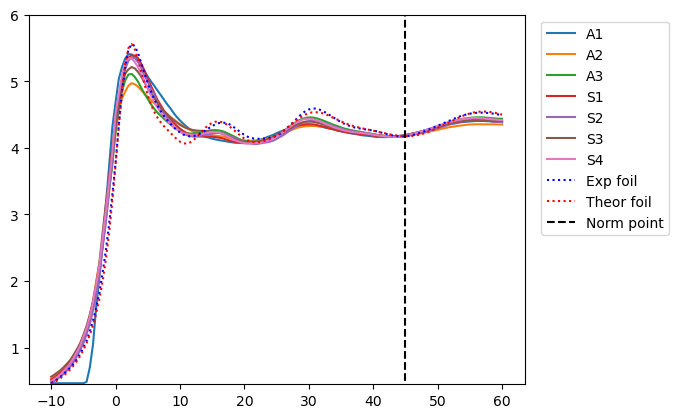

In [15]:
for k,v in spectra_data.items():
    plt.plot(E_GRID,v, label=k)

plt.plot(E_GRID, experiment_interp, 'b:', label='Exp foil')
plt.plot(E_GRID, our_theor_foil_interp, 'r:', label='Theor foil')
plt.vlines(E_GRID[norm_point_idx],0,6, color= 'black', ls='--', label='Norm point')
plt.ylim(0.45,6)
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.savefig('../images/J.T_samples_with_foil.png', dpi=600, bbox_inches='tight')
plt.show()

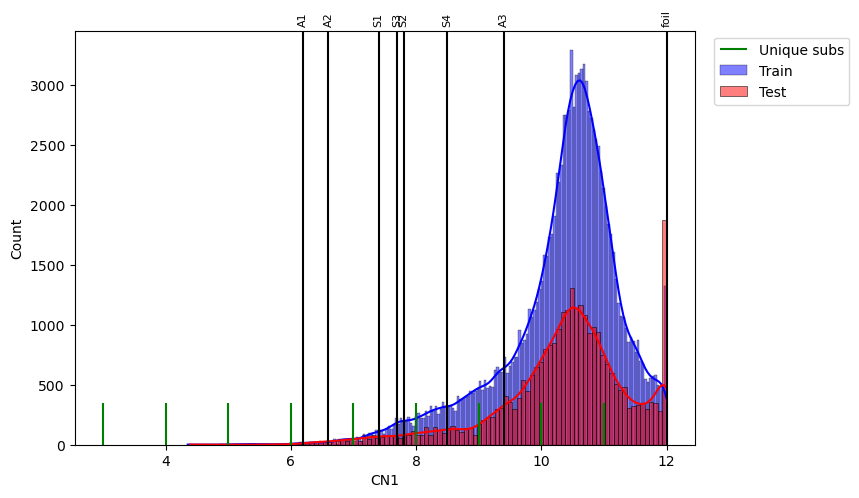

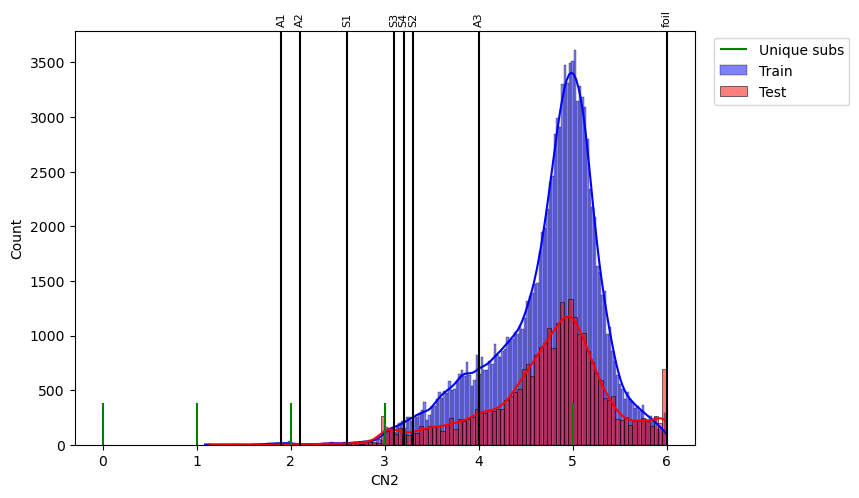

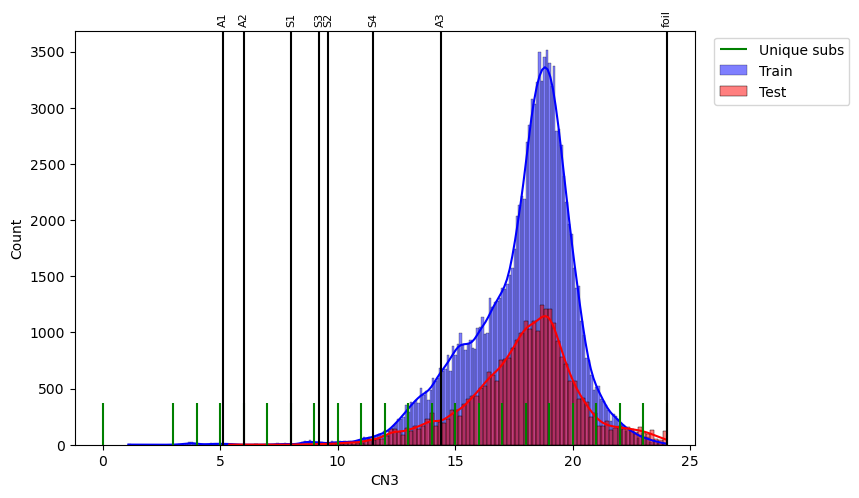

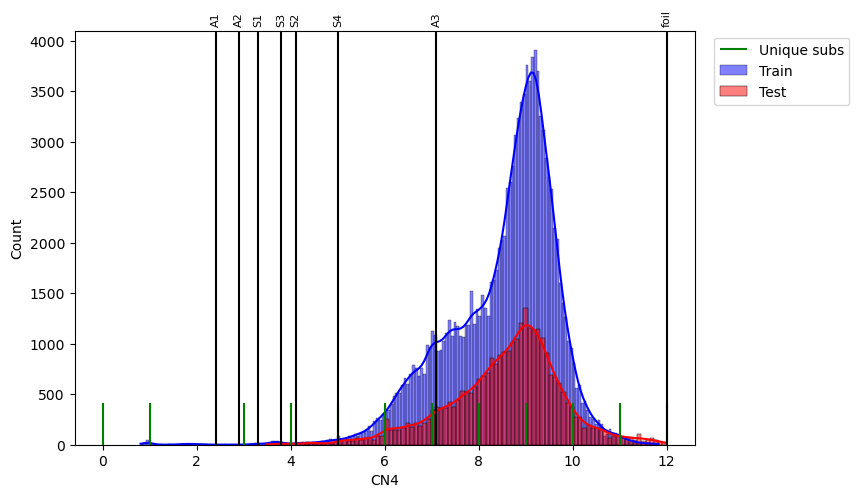

In [16]:
for ind in range(0,4,1):
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.histplot(y_train[:, ind], color='blue', ax=ax, label='Train', kde=True)
    sns.histplot(y_test[:, ind],  color='red',  ax=ax, label='Test', kde=True)
    
    trans = ax.get_xaxis_transform()
    ax.vlines(x=list(set(y_val[:, ind])), ymin=0., ymax=0.1, color='green', ls='-',  label='Unique subs', transform=trans)
    
    exp_names = cn_df.sample_name.values
    cn_i = cn_df[f'CN{ind+1}_True'].values
    for x, name in zip(cn_i, exp_names):
        ax.vlines(x=x, ymin=0, ymax=1, color='black', ls='-', transform=trans)
        ax.text(x, 1.01, name,
                rotation=90, va='bottom', ha='center', fontsize=8,
                transform=trans)
    
    plt.xlabel(f'CN{ind+1}')
    plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
    fig.subplots_adjust(top=0.8)
    plt.savefig(f'../images/J.T_CN{ind+1}_with_Data_distribution.png', dpi=600, bbox_inches='tight')
    plt.show()

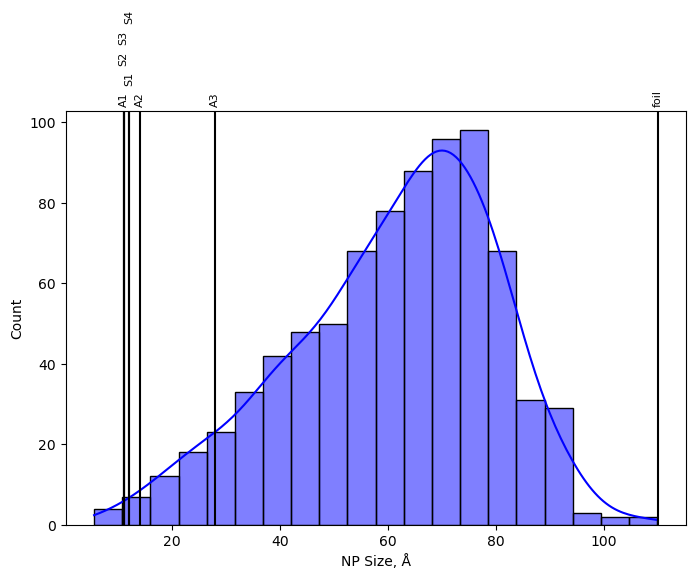

In [17]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.histplot(np_df.Pair_init_size, color='blue', ax=ax, label='Size', kde=True)

trans = ax.get_xaxis_transform()

STEP_X = 2.0   # ширина колонки в единицах данных — подберите под масштаб оси
STEP_Y = 0.05  # шаг сдвига подписи вверх (в долях оси y)

levels = defaultdict(int)

for x, name in zip(cn_df['NP_size'].values * 10, cn_df.sample_name.values):
    if x==float('inf'):
        x=110
    ax.vlines(x=x, ymin=0, ymax=1, color='black', ls='-', transform=trans)
    key = round(x / STEP_X)
    ax.text(x, 1.01 + levels[key] * STEP_Y, name,
            rotation=90, va='bottom', ha='center', fontsize=8, transform=trans)
    levels[key] += 1


plt.xlabel('NP Size, Å')
fig.subplots_adjust(top=0.8)
plt.savefig('../images/J.T.NP_sizes_with_Data_distribution.png', dpi=600, bbox_inches='tight')
plt.show()

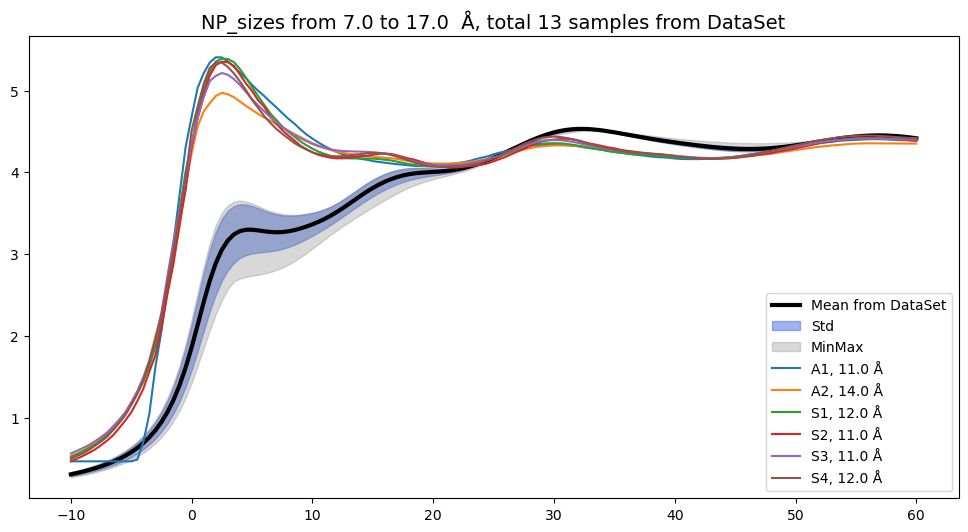

In [18]:
plot_spectrum(target_size=1.2*10)

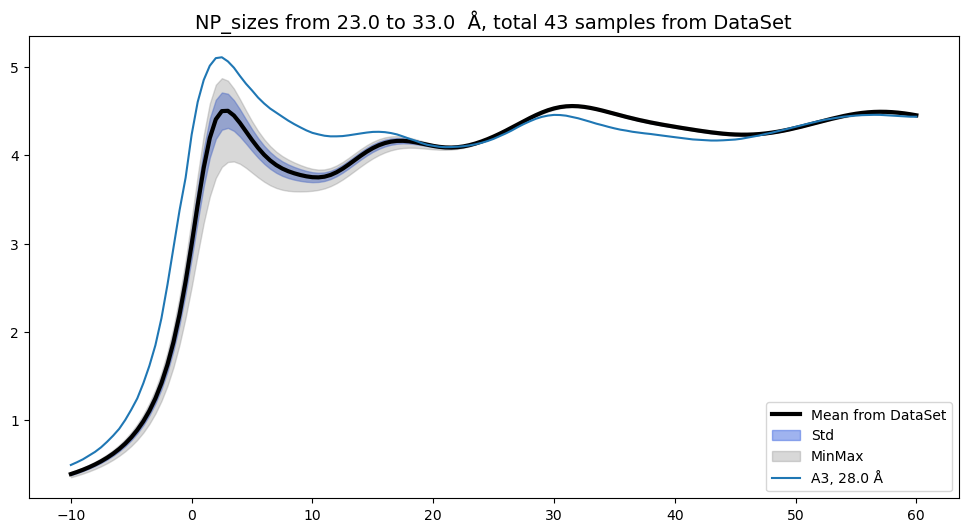

In [19]:
plot_spectrum(target_size=2.8*10)

## Проверка моделей обученных на наших данных

In [20]:
X_EXP = np.array([v for k,v in spectra_data.items()]+[experiment_interp])
y_EXP = np.array([cn_df[cn_df['sample_name']==k][['CN1_True',	'CN2_True',	'CN3_True',	'CN4_True']].values[0]
                  for k,v in spectra_data.items()])
y_EXP = np.vstack((y_EXP,[12.,  6., 24., 12.]))

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_exp_scaled = scaler.transform(X_EXP)

def mask_features(X, start=70):
    X_m = np.zeros_like(X)
    X_m[:, start:] = X[:, start:]
    return X_m

X_train_masked = mask_features(X_train_scaled)

X_val_masked = mask_features(X_val_scaled)

X_exp_masked = mask_features(X_exp_scaled)

### Ridge на полном спектре

In [21]:
%%time
# ridge = LinRegWrapper(model_type='lasso',params={'alpha':0.01}) 
ridge = LinRegWrapper(model_type='ridge')
ridge_full_data, ridge_full_metrics = collect_results(ridge, 
                                            X_train=X_train_scaled, 
                                            y_train=y_train, 
                                            X_val=X_val_scaled, 
                                            y_val=y_val, 
                                            X_exp=X_exp_scaled, 
                                            y_exp=y_EXP)

CPU times: total: 8.97 s
Wall time: 1.23 s


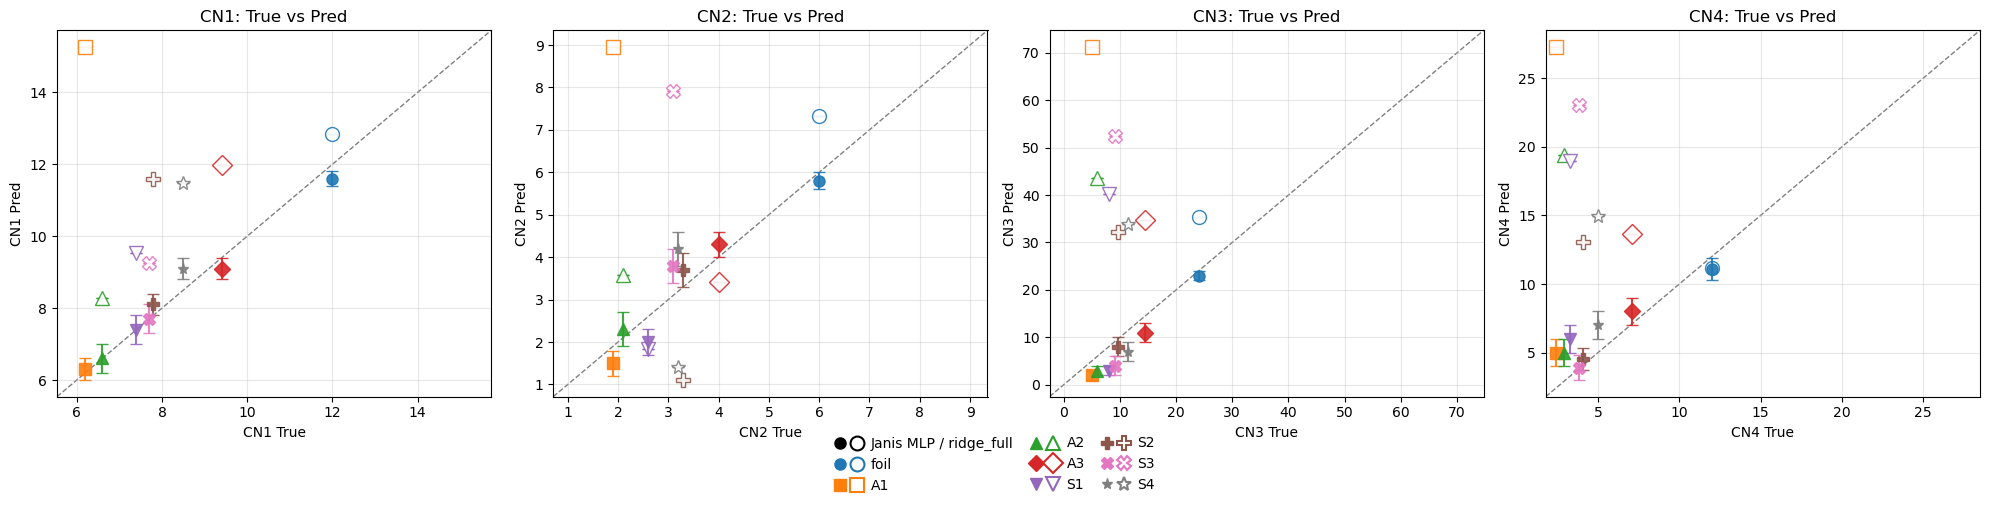

In [22]:
plot_true_vs_pred(cn_df, ridge_full_data, cn_channels=(1, 2, 3, 4), save_root='../images/', model_name='ridge_full')

### Ridge на маскированном спектре

In [23]:
%%time
# ridge = LinRegWrapper(model_type='lasso',params={'alpha':0.01})
ridge = LinRegWrapper(model_type='ridge')
ridge_masked_data, ridge_masked_metrics = collect_results(ridge, 
                                            X_train=X_train_masked, 
                                            y_train=y_train, 
                                            X_val=X_val_masked, 
                                            y_val=y_val, 
                                            X_exp=X_exp_masked, 
                                            y_exp=y_EXP)

CPU times: total: 8.78 s
Wall time: 1.19 s


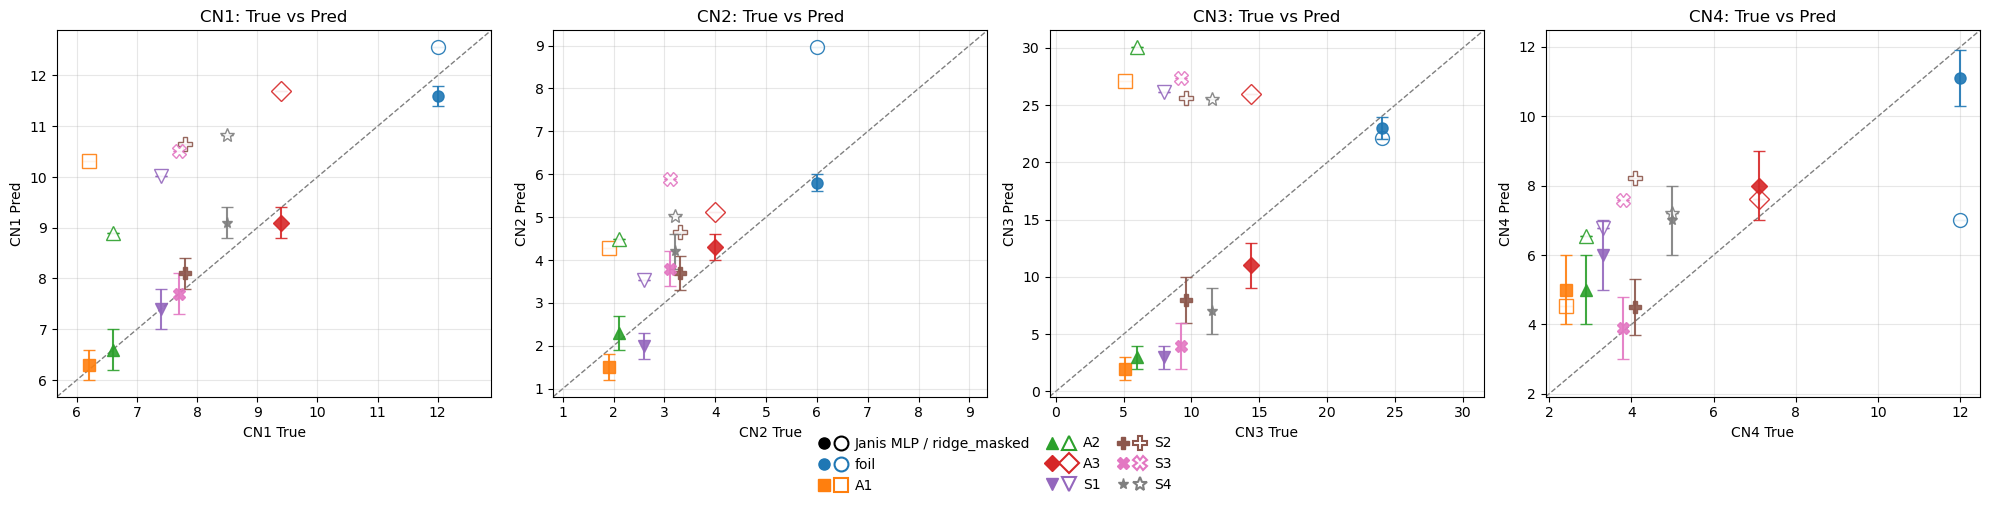

In [24]:
plot_true_vs_pred(cn_df, ridge_masked_data, cn_channels=(1, 2, 3, 4), save_root='../images/', model_name='ridge_masked')

### CNN with std

In [25]:
IN_DIM=141 # Размер входного спектра.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DROPOUT = 0.0
N_OUT = 1
KERNEL_SIZE = 5

MODEl_PARAMS = {'in_features':IN_DIM,
                'num_outputs':N_OUT,
                'kernel_size':KERNEL_SIZE,
                'dropout':DROPOUT,
               }
checkpoint_root = Path('../processed_data/Results/Scenario3_full/CNN_with_std/')

In [26]:
%%time

X_exp_torch = torch.FloatTensor(X_EXP).to(DEVICE) #.unsqueeze(1).to(DEVICE)

torch_data = {}
for cn in ['CN1','CN2','CN3','CN4']:
    tp = Path(checkpoint_root,cn)
    cpt_path = list(tp.glob('*/**/*.pth'))[0]
    pth = torch.load(cpt_path)
    
    cnn_model = XANES_CNN_Stable(**MODEl_PARAMS)
    cnn_model.to(DEVICE)
    cnn_model.load_state_dict(pth['model_state_dict'])
    
    outputs = cnn_model(X_exp_torch)
    mu, log_var = outputs
    std = torch.sqrt(torch.exp(log_var))
    mu = mu.detach().cpu().numpy()
    std = std.detach().cpu().numpy()
    torch_data[f'{cn}_mu'] = mu
    torch_data[f'{cn}_std'] = std

CPU times: total: 734 ms
Wall time: 756 ms


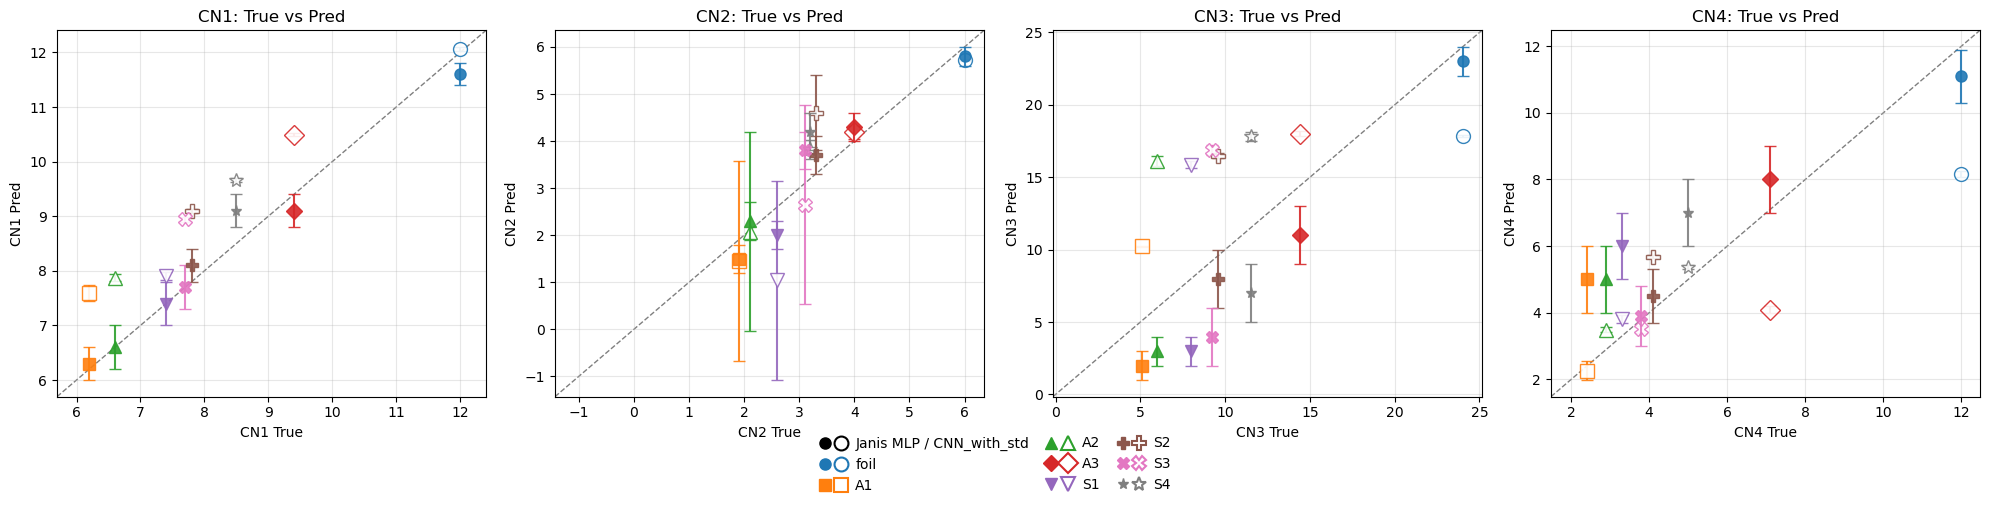

In [27]:
plot_true_vs_pred(cn_df, torch_data, cn_channels=(1, 2, 3, 4), save_root='../images/', model_name='CNN_with_std')